## 1 Sampling intervalls

count    1.351664e+07
mean     1.626587e+01
std      3.214699e+02
min      1.666667e-02
25%      5.000000e+00
50%      1.000000e+01
75%      2.998333e+01
max      4.220400e+05
Name: gap_min, dtype: float64


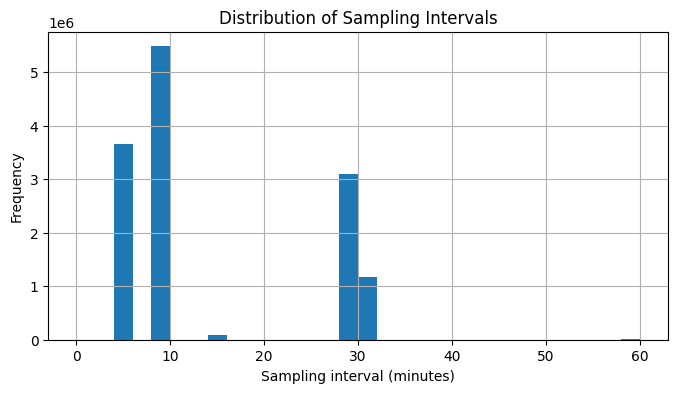

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

path = "../data/processed/dublin_bikes_all.csv"
df = pd.read_csv(path)

df["last_reported"] = pd.to_datetime(df["last_reported"], errors="coerce")

df = df.sort_values(["station_id", "last_reported"])

# gap in seconds between consecutive reports for the same station
df["gap"] = df.groupby("station_id")["last_reported"].diff()
df["gap_mn"] = df["gap"].dt.total_seconds() / 60 # in minutes (mn)
print(df["gap_mn"].describe())


plt.figure(figsize=(8,4))

df["gap_mn"].dropna().clip(upper=60).hist(bins=30)

plt.xlabel("Sampling interval (minutes)")
plt.ylabel("Frequency")
plt.title("Distribution of Sampling Intervals")

plt.show()


In [52]:
# Rolling mean per station

# Feature
df["utilisation"] = df["num_bikes_available"] / df["capacity"]

# Sort + set time index (required for time-based rolling)
df = df.sort_values(["station_id", "last_reported"]).set_index("last_reported")

# Time-based rolling mean per station (drop station_id level to align)
df["util_roll_30min"] = (
    df.groupby("station_id")["utilisation"]
      .rolling("30min", min_periods=1)
      .mean()
      .reset_index(level=0, drop=True)   # <-- critical line
)

# Restore last_reported as a column
df = df.reset_index()

## 3- Weekly view for one station

count                         1205
mean     0 days 00:08:21.659751037
std      0 days 00:21:41.639867985
min                0 days 00:05:00
25%                0 days 00:05:00
50%                0 days 00:05:00
75%                0 days 00:10:00
max                0 days 09:30:00
Name: last_reported, dtype: object
CLARENDON ROW


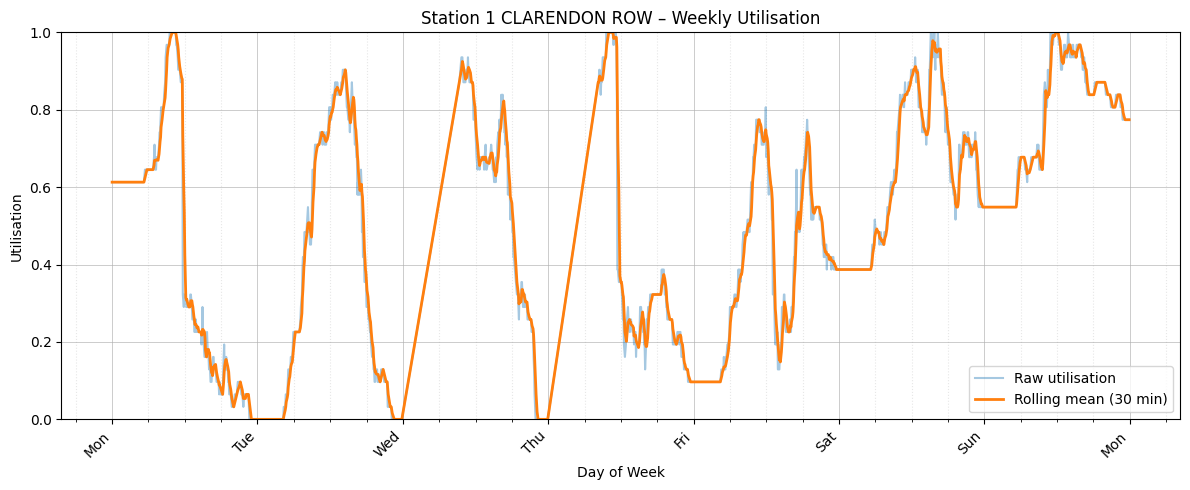

In [59]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
import matplotlib.ticker as ticker




start = pd.Timestamp("2024-06-03")
end   = pd.Timestamp("2024-06-10")

station_id = 1

station_df = df[
    (df["station_id"] == station_id) &
    (df["last_reported"] >= start) &
    (df["last_reported"] < end)
].sort_values("last_reported")

# # Checks on data missing / mismatch...
## this is on the original df, for all years for this specific station, to check if the sampling interval is consistent
print(station_df["last_reported"].diff().describe())


station_name = station_df["name"].iloc[0]
print(station_name)
week = station_df[(station_df["last_reported"] >= start) & (station_df["last_reported"] < end)]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(week["last_reported"], week["utilisation"], alpha=0.4, label="Raw utilisation")
ax.plot(week["last_reported"], week["util_roll_30min"], linewidth=2, label="Rolling mean (30 min)")

# Fix y-axis
ax.set_ylim(0, 1.0)

# Major ticks: one per day (at midnight)
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%a"))  # Mon Tue Wed...

# Minor ticks = every 6 hours
ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[0,6,12,18]))

# Grid
ax.grid(True, which="major", linewidth=0.5, alpha=0.9)
ax.grid(True, which="minor", linestyle=":", alpha=0.3)

# Rotate only the major tick labels
for label in ax.get_xticklabels(which="major"):
    label.set_rotation(45)
    label.set_ha("right")

ax.set_title(f"Station {station_id} {station_name} – Weekly Utilisation")
ax.set_xlabel("Day of Week")
ax.set_ylabel("Utilisation")
ax.legend()

# Grid: only on major ticks to avoid vertical stripe overload
# ax.grid(True, which="major", alpha=0.3)

plt.tight_layout()
plt.show()